In [2]:
%load_ext autoreload
%autoreload 2

import torch
from torch import nn
from torch.nn import functional as F

import matplotlib.pyplot as plt
import numpy as np

from src.utils import DEVICE, CKPT_DIR, FIG_DIR, set_seed, save_history, load_history, show_grid
from src.data import get_dataloaders, CLASSES
from src.metrics import recon_metrics, latency_ms
from src.train import train_classifier, evaluate_classifier, extract_latents, fit

 ### Dataset Preparation

In [3]:
set_seed(42) # random, numpy, torch

BATCH_SIZE = 256
EPOCHS = 20

# 70k samples (train 60k + test 10k), stratified split 80:10:10
# batch 256, shuffle=True for train and shuffle=False for validation/test
train_dl, val_dl, test_dl = get_dataloaders(batch_size=BATCH_SIZE)

print(len(train_dl.dataset), len(val_dl.dataset), len(test_dl.dataset))
print(DEVICE)

56000 7000 7000
cuda


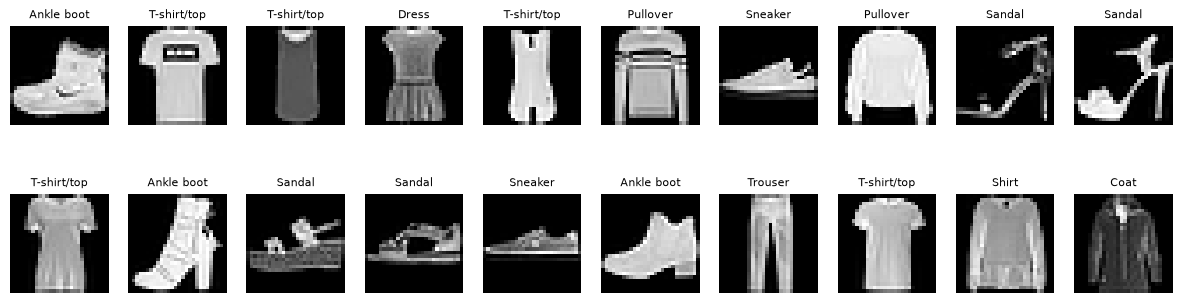

In [4]:
# test show image
x = train_dl.dataset.dataset.datasets[0].data
classes = train_dl.dataset.dataset.datasets[0].classes
y_idx = train_dl.dataset.dataset.datasets[0].targets
y = [classes[i] for i in y_idx]

sample_x, sample_y = x[:20], y[:20]

fig, axes = plt.subplots(2, 10, figsize=(15, 4))
for c, ax in enumerate(axes.flat):
    ax.imshow(sample_x[c].numpy(), cmap="gray")
    ax.set_title(sample_y[c], fontsize=8)
    ax.axis("off")
plt.show()

MLP: step 1 (train classifier)

In [5]:
# base MLP model to recreate encoder architecture: 784 -> 256 -> 64 -> 10
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 256)
        self.fc2 = nn.Linear(256, 64)
        self.fc3 = nn.Linear(64, 10)

    def forward(self, x):
        x = x.view(x.size(0), -1)  # (B,1,28,28) -> (B,784) flatten
        h = F.relu(self.fc1(x))
        z = F.relu(self.fc2(h))    # latent
        return self.fc3(z), z      # logits, z

In [6]:
# Train, Validate, Test
set_seed(42)
model = MLP().to(DEVICE)
opt = torch.optim.Adam(model.parameters(), lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0)

history = train_classifier("mlp", model, opt, train_dl, val_dl, epochs=EPOCHS)

test_loss, test_acc = evaluate_classifier(model, test_dl)
print("Test Loss    :", test_loss)
print("Test Accuracy:", test_acc)

Epoch   1: train_loss=0.6765 | train_acc=0.7708 | val_loss=0.4835 | val_acc=0.8289 | 4.3s
Epoch   2: train_loss=0.4343 | train_acc=0.8473 | val_loss=0.4201 | val_acc=0.8491 | 4.0s
Epoch   3: train_loss=0.3922 | train_acc=0.8613 | val_loss=0.3978 | val_acc=0.8551 | 5.2s
Epoch   4: train_loss=0.3600 | train_acc=0.8701 | val_loss=0.3765 | val_acc=0.8626 | 5.0s
Epoch   5: train_loss=0.3410 | train_acc=0.8769 | val_loss=0.3595 | val_acc=0.8693 | 4.9s
Epoch   6: train_loss=0.3255 | train_acc=0.8824 | val_loss=0.3527 | val_acc=0.8733 | 4.9s
Epoch   7: train_loss=0.3107 | train_acc=0.8869 | val_loss=0.3401 | val_acc=0.8771 | 5.1s
Epoch   8: train_loss=0.2954 | train_acc=0.8908 | val_loss=0.3525 | val_acc=0.8706 | 5.1s
Epoch   9: train_loss=0.2922 | train_acc=0.8930 | val_loss=0.3340 | val_acc=0.8789 | 4.8s
Epoch  10: train_loss=0.2776 | train_acc=0.8987 | val_loss=0.3343 | val_acc=0.8810 | 5.0s
Epoch  11: train_loss=0.2692 | train_acc=0.9015 | val_loss=0.3288 | val_acc=0.8777 | 5.2s
Epoch  12:

In [7]:
# save weights (for Step 2-3)
W1 = model.fc1.weight.detach()   # (256, 784)
W2 = model.fc2.weight.detach()   # (64, 256)
W3 = model.fc3.weight.detach()   # (10, 64)
torch.save({"W1": W1.cpu(), "W2": W2.cpu(), "W3": W3.cpu()}, CKPT_DIR / "mlp_weights.pt")

# save z_mlp of the test set (for Step 3-5)
z_mlp, y_test = extract_latents(model, test_dl)   # (7000, 64), (7000,)
torch.save({"z": z_mlp, "y": y_test}, CKPT_DIR / "z_mlp.pt")
print(W1.shape, W2.shape, W3.shape, z_mlp.shape)

torch.Size([256, 784]) torch.Size([64, 256]) torch.Size([10, 64]) torch.Size([7000, 64])


MLP: Step 2 (Top-Down Weight Transportation -> reverse from one hot to pixels)

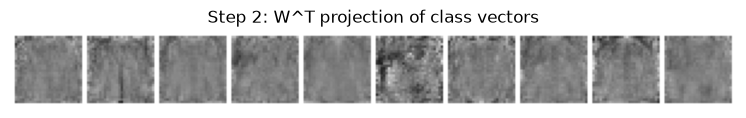

In [10]:
Y = torch.eye(10, device=W3.device) # 10 sample one hot 1 per class

z_hat  = F.relu(Y @ W3)             # (10,10) @ (10,64)   -> (10,64)  
h1_hat = F.relu(z_hat @ W2)         # (10,64) @ (64,256)  -> (10,256) 
x_hat  = torch.sigmoid(h1_hat @ W1) # (10,256) @ (256,784)-> (10,784) 

show_grid(x_hat.view(10, 1, 28, 28), nrow=10, title="Step 2: W^T projection of class vectors")

MLP: Step 3 (reverse latent to pixels)

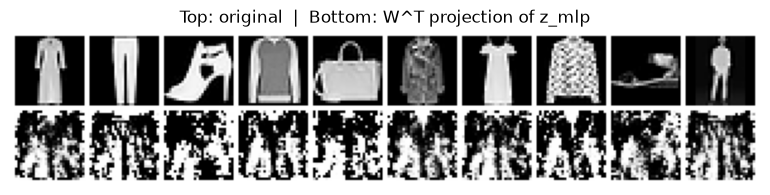

In [11]:
x_test, y_lbl = next(iter(test_dl)) # first test batch, same order as z_mlp
x_orig = x_test[:10].to(W2.device)  # (10,1,28,28)
z = z_mlp[:10].to(W2.device)        # (10,64), z of exactly those 10 images

h1_back = F.relu(z @ W2)            # (10,64) @ (64,256)  -> (10,256)
x_back = torch.sigmoid(h1_back @ W1)# (10,256) @ (256,784) -> (10,784)

show_grid(torch.cat([x_orig, x_back.view(10, 1, 28, 28)]), nrow=10,
          title="Top: original  |  Bottom: W^T projection of z_mlp")

MLP: Step 4 part 1 (frozen mlp classifier + decoder)

In [12]:
# 64 -> 256 -> 784
class Decoder(nn.Module):
    def __init__(self, z_dim=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(z_dim, 256), nn.ReLU(),
            nn.Linear(256, 784), nn.Sigmoid())
    def forward(self, z):
        return self.net(z)

In [13]:
def frozen_dec_loss(decoder, x, y):
    with torch.no_grad():
        _, z = model(x) # get latent space from encoder
    x_hat = decoder(z)  # get reconstructed pixels
    return F.mse_loss(x_hat, x.view(x.size(0), -1))

# freeze encoder weights
for p in model.parameters():
    p.requires_grad = False
model.eval()

set_seed(42)
decoder = Decoder().to(DEVICE)
opt_dec = torch.optim.Adam(decoder.parameters(), lr=1e-3)

# train, validate, and eval
hist_dec = fit("mlp_frozen_decoder", decoder, frozen_dec_loss, opt_dec, train_dl, val_dl, epochs=EPOCHS)
res_mlp_dec = recon_metrics(lambda x: decoder(model(x)[1]))

mlp_frozen_decoder ep   1 | train 0.04146 | val 0.02791 | 5.7s
mlp_frozen_decoder ep   2 | train 0.02558 | val 0.02370 | 5.8s
mlp_frozen_decoder ep   3 | train 0.02260 | val 0.02216 | 5.6s
mlp_frozen_decoder ep   4 | train 0.02112 | val 0.02061 | 5.6s
mlp_frozen_decoder ep   5 | train 0.02024 | val 0.01999 | 5.5s
mlp_frozen_decoder ep   6 | train 0.01961 | val 0.01943 | 4.5s
mlp_frozen_decoder ep   7 | train 0.01914 | val 0.01910 | 5.5s
mlp_frozen_decoder ep   8 | train 0.01876 | val 0.01864 | 4.9s
mlp_frozen_decoder ep   9 | train 0.01845 | val 0.01836 | 5.7s
mlp_frozen_decoder ep  10 | train 0.01814 | val 0.01828 | 6.0s
mlp_frozen_decoder ep  11 | train 0.01789 | val 0.01796 | 5.6s
mlp_frozen_decoder ep  12 | train 0.01772 | val 0.01770 | 5.2s
mlp_frozen_decoder ep  13 | train 0.01749 | val 0.01758 | 4.9s
mlp_frozen_decoder ep  14 | train 0.01731 | val 0.01739 | 4.9s
mlp_frozen_decoder ep  15 | train 0.01717 | val 0.01724 | 5.6s
mlp_frozen_decoder ep  16 | train 0.01704 | val 0.01726

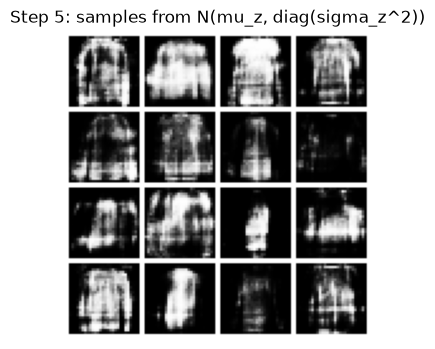

In [14]:
mu, sigma = z_mlp.mean(0), z_mlp.std(0)                  # per-dimension, shape (64,)
set_seed(42)
z_rand = (mu + sigma * torch.randn(16, 64)).to(DEVICE)
imgs = decoder(z_rand).view(16, 1, 28, 28)
show_grid(imgs, nrow=4, title="Step 5: samples from N(mu_z, diag(sigma_z^2))")

Vanilla Autoencoder 

In [15]:
# 784 -> 256 -> 64 -> 256 -> 784
class AE(nn.Module):
    def __init__(self, z_dim=64):
        super().__init__()
        self.enc = nn.Sequential(
            nn.Flatten(),                         # (B,1,28,28) -> (B,784)
            nn.Linear(784, 256), nn.ReLU(),
            nn.Linear(256, z_dim), nn.ReLU())     # latent h, (B,64)
        self.dec = nn.Sequential(
            nn.Linear(z_dim, 256), nn.ReLU(),
            nn.Linear(256, 784), nn.Sigmoid())    # pixels in [0,1], (B,784)

    def forward(self, x):
        h = self.enc(x)
        return self.dec(h), h # x_hat, latent

def ae_loss(model, x, y):
    x_hat, _ = model(x)
    return F.mse_loss(x_hat, x.flatten(1))

In [16]:
set_seed(42)
ae = AE().to(DEVICE)
opt_ae = torch.optim.Adam(ae.parameters(), lr=1e-3)
print("parameters:", sum(p.numel() for p in ae.parameters()))

# train and validate
hist_ae = fit("ae", ae, ae_loss, opt_ae, train_dl, val_dl, epochs=EPOCHS)

parameters: 435536
ae ep   1 | train 0.04663 | val 0.02386 | 3.8s
ae ep   2 | train 0.02125 | val 0.01926 | 5.3s
ae ep   3 | train 0.01810 | val 0.01725 | 4.6s
ae ep   4 | train 0.01633 | val 0.01565 | 4.5s
ae ep   5 | train 0.01502 | val 0.01453 | 4.5s
ae ep   6 | train 0.01406 | val 0.01383 | 4.5s
ae ep   7 | train 0.01334 | val 0.01309 | 4.8s
ae ep   8 | train 0.01278 | val 0.01256 | 5.3s
ae ep   9 | train 0.01233 | val 0.01231 | 4.9s
ae ep  10 | train 0.01189 | val 0.01178 | 5.1s
ae ep  11 | train 0.01158 | val 0.01159 | 4.9s
ae ep  12 | train 0.01132 | val 0.01127 | 4.6s
ae ep  13 | train 0.01102 | val 0.01100 | 4.7s
ae ep  14 | train 0.01082 | val 0.01079 | 4.6s
ae ep  15 | train 0.01059 | val 0.01072 | 4.7s
ae ep  16 | train 0.01040 | val 0.01052 | 4.5s
ae ep  17 | train 0.01021 | val 0.01022 | 4.5s
ae ep  18 | train 0.01008 | val 0.01013 | 4.7s
ae ep  19 | train 0.00993 | val 0.00998 | 4.6s
ae ep  20 | train 0.00977 | val 0.00981 | 4.6s


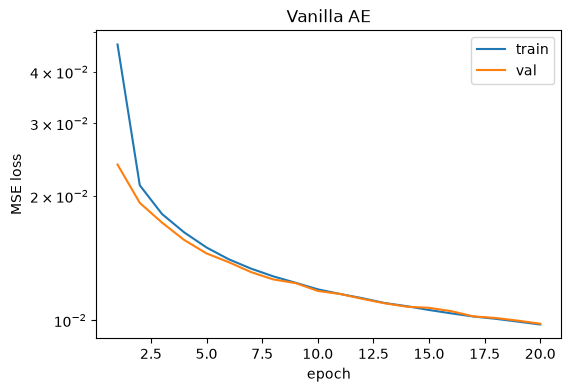

In [17]:
# loss curves 
ep = range(1, len(hist_ae["train_loss"]) + 1)
plt.figure(figsize=(6, 4))
plt.plot(ep, hist_ae["train_loss"], label="train")
plt.plot(ep, hist_ae["val_loss"], label="val")
plt.yscale("log")
plt.xlabel("epoch")
plt.ylabel("MSE loss")
plt.title("Vanilla AE")
plt.legend()
plt.savefig(FIG_DIR / "ae_loss.png", dpi=300, bbox_inches="tight")
plt.show()

z_ae, _ = extract_latents(ae, test_dl) 
torch.save({"z": z_ae, "y": y_test}, CKPT_DIR / "z_ae.pt")

MLP: Step 4 part 2 (compare with AE)

In [18]:
# reconstruction metrics, AE vs MLP frozen + decoder
ae.eval()
decoder.eval()

res_ae      = recon_metrics(lambda x: ae(x)[0])
res_mlp_dec = recon_metrics(lambda x: decoder(model(x)[1]))

x64 = next(iter(test_dl))[0][:64].to(DEVICE)
lat_ae = latency_ms(lambda: ae(x64)) # encode + decode, one batch of 64
time_ae = np.mean(hist_ae["epoch_time"])

print(f"{'':16}{'MSE':>9}{'PSNR':>9}{'SSIM':>8}")
print(f"{'Vanilla AE':16}{res_ae['mse']:9.5f}{res_ae['psnr']:9.2f}{res_ae['ssim']:8.4f}")
print(f"{'MLP + decoder':16}{res_mlp_dec['mse']:9.5f}{res_mlp_dec['psnr']:9.2f}{res_mlp_dec['ssim']:8.4f}")
print(f"train time/epoch: {time_ae:.2f} s | latency: {lat_ae:.3f} ms / batch 64")

                      MSE     PSNR    SSIM
Vanilla AE        0.00969    21.05  0.8053
MLP + decoder     0.01661    18.50  0.7029
train time/epoch: 4.69 s | latency: 0.131 ms / batch 64


[11, 1, 3, 0, 5, 8, 7, 20, 4, 2] tensor([[[[0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          ...,
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000]]],


        [[[0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          ...,
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000]]],


        [[[0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
     

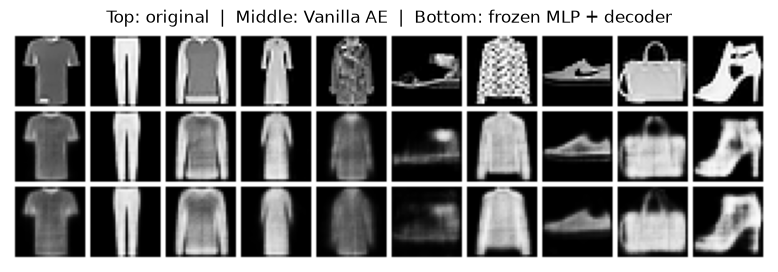

In [21]:
# one test image per class: original / Vanilla AE / MLP frozen decoder
x_all, y_all = next(iter(test_dl))
pick = [(y_all == c).nonzero()[0].item() for c in range(10)]
x_pick = x_all[pick].to(DEVICE) # (10,1,28,28)
print(pick, x_pick)

with torch.no_grad():
    rec_ae  = ae(x_pick)[0].view(-1, 1, 28, 28)
    rec_mlp = decoder(model(x_pick)[1]).view(-1, 1, 28, 28)

show_grid(torch.cat([x_pick, rec_ae, rec_mlp]), nrow=10,
          title="Top: original  |  Middle: Vanilla AE  |  Bottom: frozen MLP + decoder",
          path=FIG_DIR / "ae_vs_mlp_recon.png")

Sparse Autoencoder 

Generative Adversarial Network (GAN) 

Variational Autoencoder (VAE) 

Deep Convolutional GAN (DCGAN) 

Denoising Diffusion Probabilistic Models (DDPM)

In [20]:
metrics = [
    "Arsitektur Model",
    "Dim Laten",
    "Training Time / Epoch (s)",
    "Latency (ms / batch 64)",
    "Test MSE",
    "Test PSNR (dB)",
    "FID Score",
    "Kestabilan Training"
]